# Currawong: geometry and mass

Run with the kernel **AeroPlan AeroSandbox** (made by `python -m aeroplan setup AeroSandbox`).
The notebook reads the ADH source tree `aircraft/currawong/` and changes nothing. Plots go to
`AeroSandbox/work/currawong/lab/`.

1. What the AeroSandbox model of the aircraft looks like.
2. The mass model (Master Specification Sheet, via the SpecSheet spoke): where the mass is and how well each part is known.
3. The CG and the static margin for each configuration.

In [2]:
import sys, warnings
sys.path.insert(0, "..")                    # AeroSandbox/lab.py
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import lab

pd.set_option("display.float_format", lambda v: f"{v:.4f}")
L = lab.load("currawong")                   # reads aircraft/currawong (read only)
lab.style()                                 # after the load: importing aerosandbox resets the matplotlib style
mrp, c_ref, s_ref = L.ref["xyz_ref"], L.ref["c_m"], L.ref["s_m2"]
cg = lab.rollup(L.masses)["cg"]
mac = lab.mac_geometry(L)
print(L)

Lab(aircraft='currawong', airplane=Airplane 'Currawong' (3 wings, 1 fuselage), flow5=<aeroplan.daveml_eval.Model object at 0x79365bd2f8c0>, out=PosixPath('/home/aquaguy/Github/Aeroplan/AeroSandbox/work/currawong/lab'))


## 1. Geometry
AeroSandbox against the ADH reference. The tail incidence (ry) is in the section twist.

In [3]:
rows = []
for w in L.airplane.wings:
    rows.append({"surface": w.name, **lab.planform_numbers(w)})
geo = pd.DataFrame(rows).set_index("surface")
display(geo)
print(f"ADH reference: S {s_ref} m2, b {L.ref['b_m']} m, c {c_ref} m, MRP x {mrp[0]:+.4f} m (the aero model is about this point)")
print(f"main wing MAC {mac['mac_m']:.4f} m, MAC leading edge x {mac['x_le_m']:+.4f} m, quarter chord x {mac['x_quarter_m']:+.4f} m")
print("section twist [deg] (chord line angle, nose up positive):")
for w in L.airplane.wings:
    print(f"  {w.name:10s}", [round(x.twist, 2) for x in w.xsecs])

,area_m2,span_m,mac_m,AR
surface,,,,
wing_main,1.0745,3.3016,0.3298,10.1441
htail,0.1642,0.7460,0.2210,3.3896
fin,0.1067,0.4390,0.2440,1.8066


ADH reference: S 1.0762 m2, b 3.3 m, c 0.33 m, MRP x +0.1291 m (the aero model is about this point)
main wing MAC 0.3298 m, MAC leading edge x -0.0799 m, quarter chord x +0.0025 m
section twist [deg] (chord line angle, nose up positive):
  wing_main  [4.0, 1.5, 1.33, 1.17, -0.17, -0.46, -0.85]
  htail      [-2.6, -2.6, -2.6]
  fin        [0.0, 0.0, 0.0]


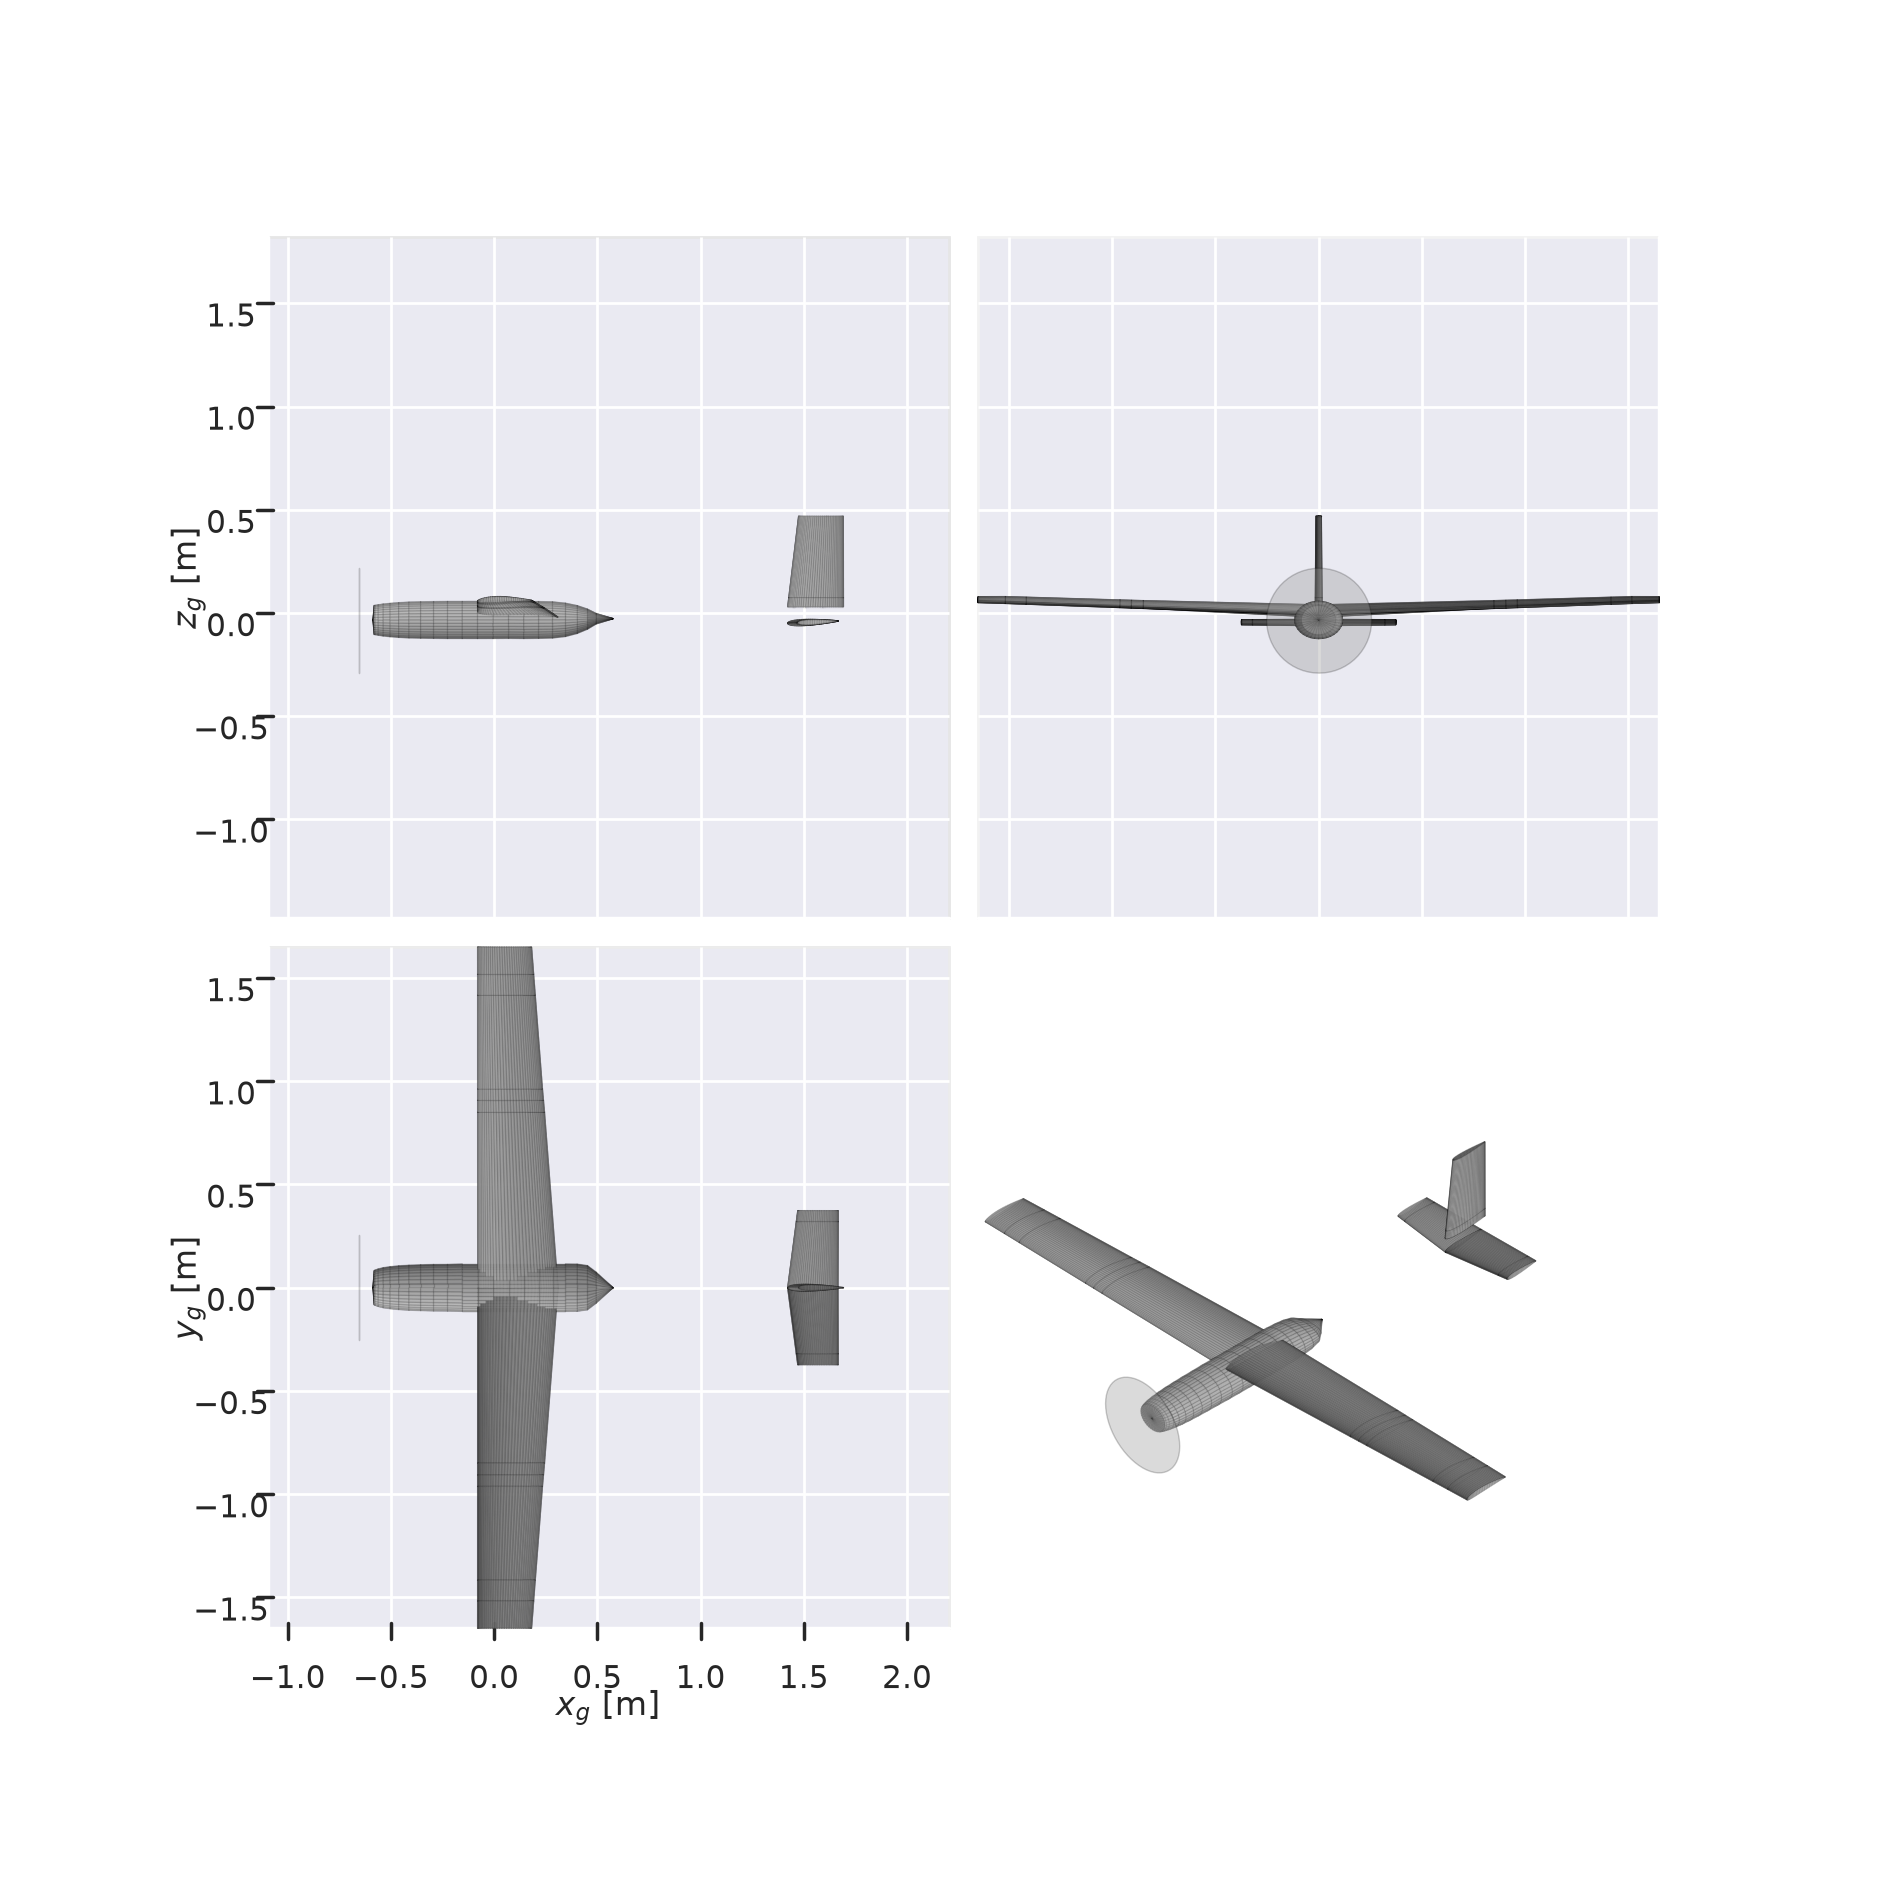

In [4]:
L.airplane.draw_three_view(show=False)
plt.gcf().savefig(L.out / "three_view.png", dpi=150)
plt.show()

Interactive 3D view. The marker area follows the mass of each point mass. Click a group in the legend to hide it.

In [5]:
fig = lab.figure_3d(L)
fig.write_html(str(L.out / "airplane_3d.html"), include_plotlyjs="cdn")
fig.show()

Top view with the mass distribution. The dashed line is the quarter-chord line of the main wing.

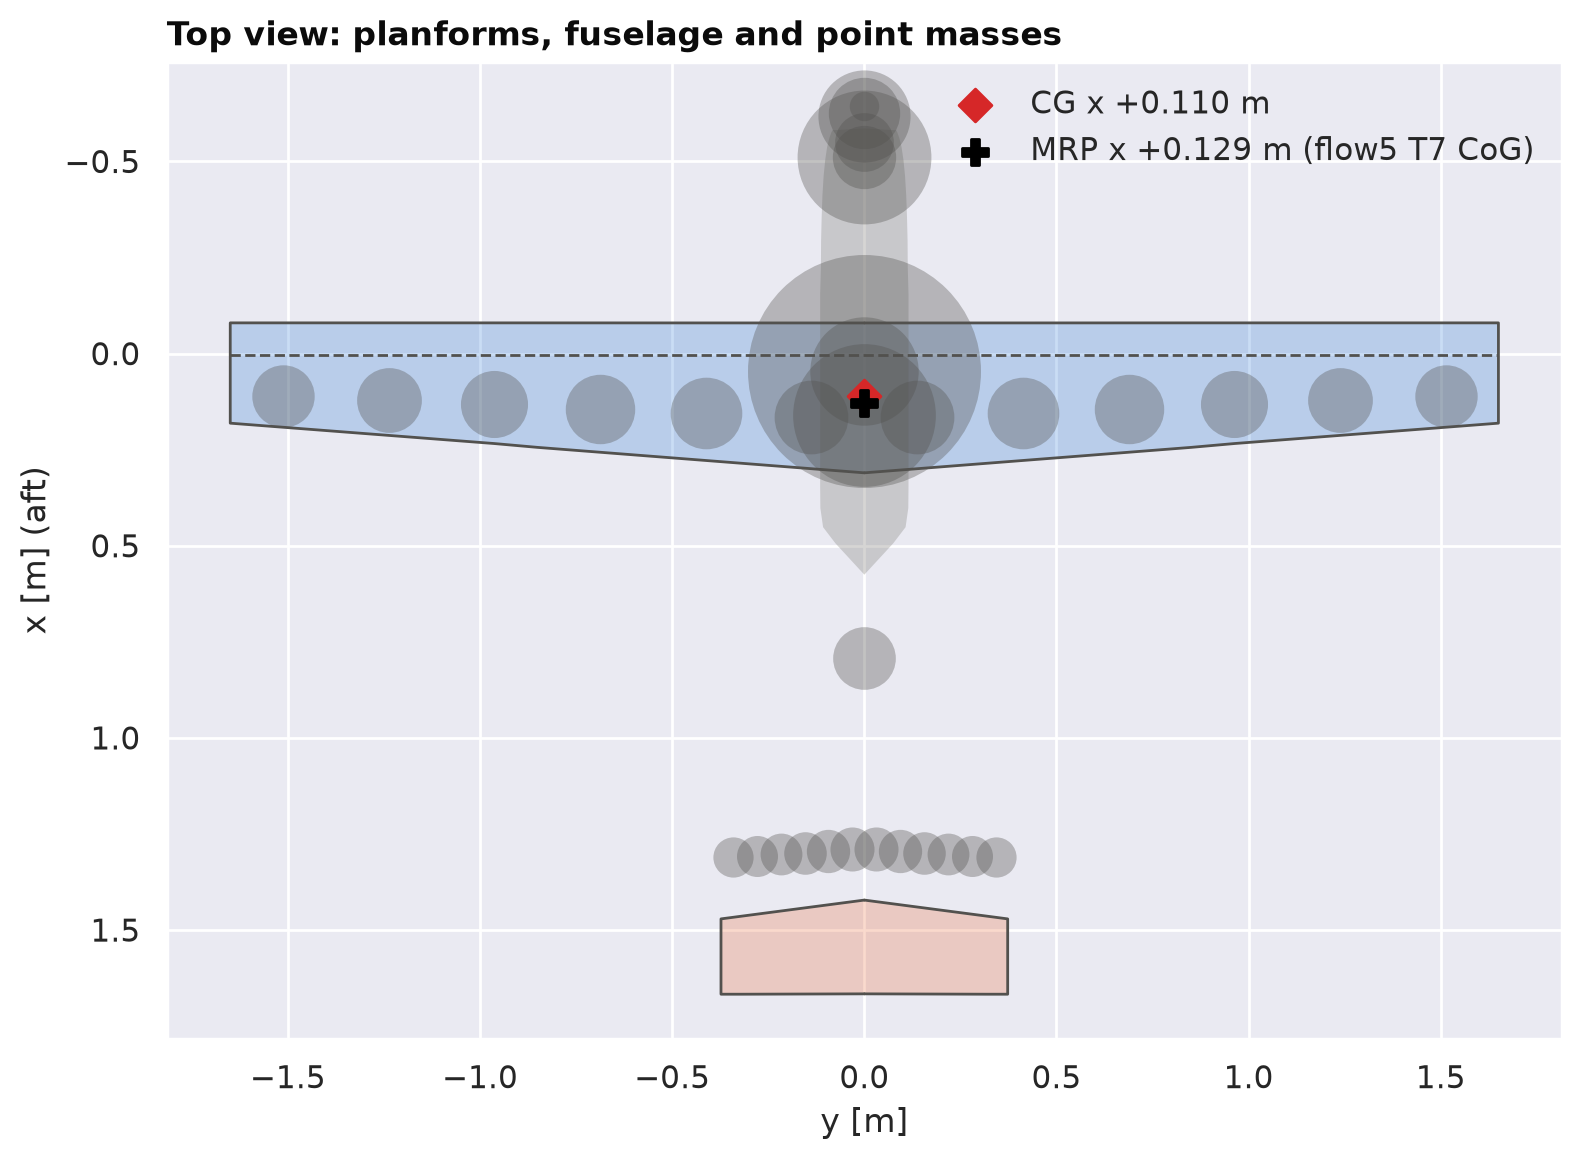

In [6]:
fig, ax = plt.subplots(figsize=(9, 6.5))
for s in L.spec["surfaces"]:
    le = np.array([x["xyz_le"] for x in s["sections"]]); ch = np.array([x["chord"] for x in s["sections"]])
    te_x = le[:, 0] + ch
    if s["name"] == "fin":
        continue
    for sign in ((1, -1) if s["mirror"] else (1,)):
        poly_y = np.concatenate([sign * le[:, 1], (sign * le[:, 1])[::-1]])
        poly_x = np.concatenate([le[:, 0], te_x[::-1]])
        ax.fill(poly_y, poly_x, color="#2a78d6" if s["name"] == "wing_main" else "#eb6834", alpha=0.25, lw=0)
        ax.plot(poly_y, poly_x, color="#52514e", lw=1)
fr = L.spec["fuselage"]["frames"]
fx = [f[0][0] for f in fr]; fw = [max(abs(p[1]) for p in f) for f in fr]
ax.fill(np.concatenate([fw, -np.array(fw)[::-1]]), np.concatenate([fx, fx[::-1]]), color="#8a8984", alpha=0.35, lw=0)
for p in L.masses:
    ax.scatter(p["xyz"][1], p["xyz"][0], s=2500 * p["mass_kg"], color="#52514e", alpha=0.35, lw=0)
ax.plot([-1.65, 1.65], [mac["x_quarter_m"]] * 2, "--", color="#52514e", lw=1)
ax.scatter([0], [cg[0]], marker="D", s=70, color="#d62728", zorder=5, label=f"CG x {cg[0]:+.3f} m")
ax.scatter([0], [mrp[0]], marker="P", s=90, color="black", zorder=5, label=f"MRP x {mrp[0]:+.3f} m (flow5 T7 CoG)")
ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_xlabel("y [m]"); ax.set_ylabel("x [m] (aft)")
ax.set_title("Top view: planforms, fuselage and point masses"); ax.legend(loc="upper right")
fig.savefig(L.out / "top_view.png", dpi=150); plt.show()

## 2. Mass model

Source: `Currawong Master Specification Sheet.xlsx` (sheet `1st Airframe`, positions from `CG Calcs 1 forward tank`).
The mass of each subassembly is a weighed total. The x position comes from the CG sheet. y and z are zero, because the
sheet has no y or z (a stand-in). `placeholder` marks a point mass whose mass is partly a made-up or not-weighed item.

,mass_kg,points,placeholder_kg,x_cg_m,share_%
group,,,,,
FUSELAGE,2.8140,1,2.8140,0.0444,26.1686
WINGS,2.9000,12,0.0000,0.1394,26.9684
LANDING_GEAR,1.3200,2,0.2640,0.0026,12.2753
TAIL,1.3100,13,1.3100,1.2211,12.1823
AVIONICS,0.6090,1,0.6090,0.0444,5.6634
PROPULSION,1.8003,5,1.1073,-0.5438,16.7421


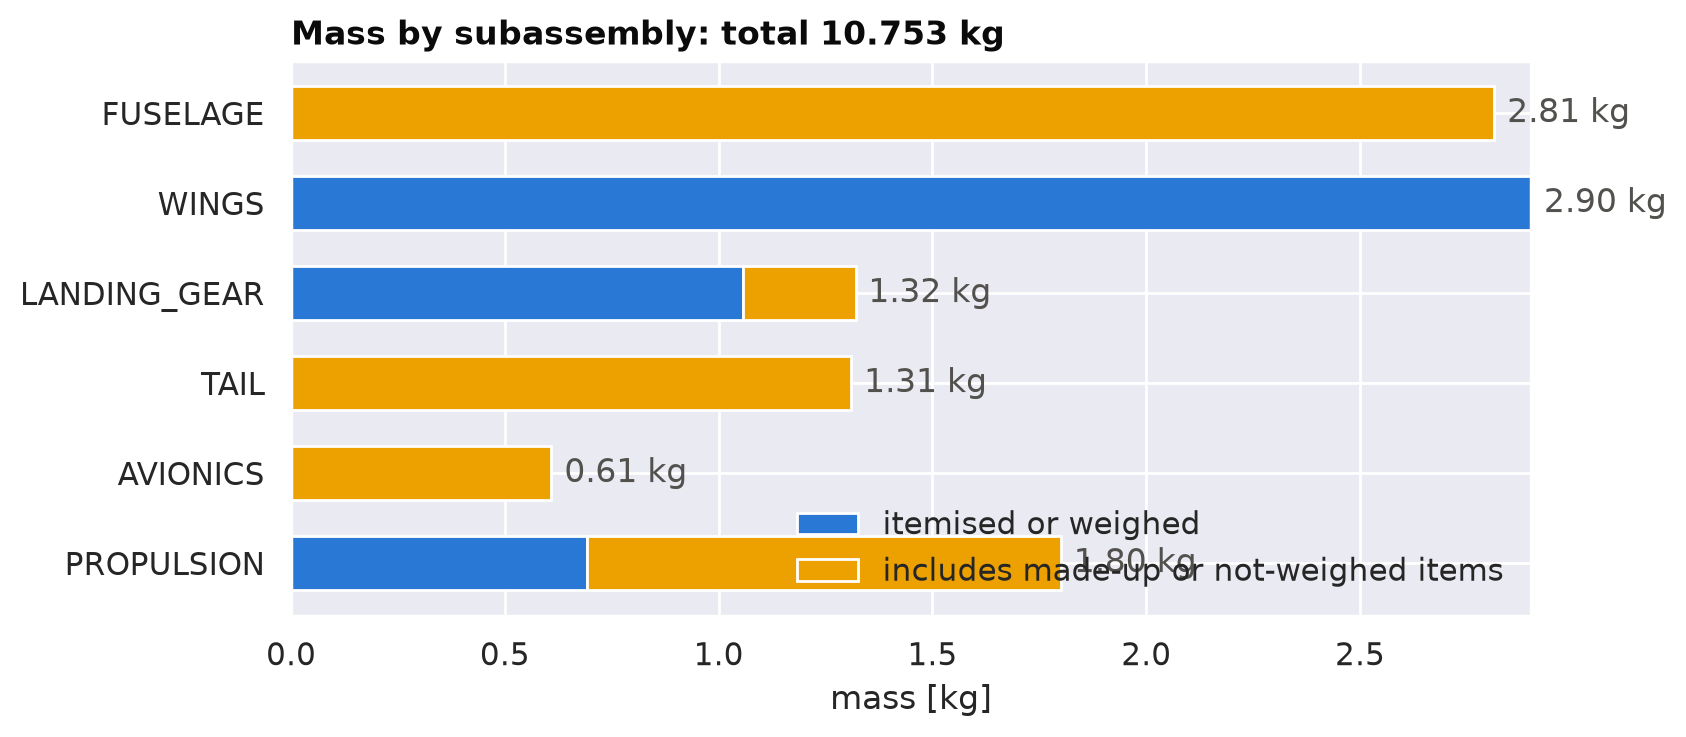

In [7]:
df = pd.DataFrame(L.masses)
df["group"] = df.tag.map(lab.group_of)
g = df.groupby("group", sort=False).agg(mass_kg=("mass_kg", "sum"), points=("tag", "count"))
g["placeholder_kg"] = df[df.placeholder].groupby("group").mass_kg.sum().reindex(g.index).fillna(0.0)
g["x_cg_m"] = df.groupby("group", sort=False).apply(lambda d: (d.mass_kg * d.xyz.map(lambda p: p[0])).sum() / d.mass_kg.sum())
g["share_%"] = 100 * g.mass_kg / g.mass_kg.sum()
display(g)
fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(g))[::-1]
ax.barh(y, g.mass_kg - g.placeholder_kg, color="#2a78d6", label="itemised or weighed", height=0.6)
ax.barh(y, g.placeholder_kg, left=g.mass_kg - g.placeholder_kg, color="#eda100", label="includes made-up or not-weighed items", height=0.6)
for yi, m in zip(y, g.mass_kg):
    ax.text(m + 0.03, yi, f"{m:.2f} kg", va="center", color="#52514e")
ax.set_yticks(y, g.index); ax.set_xlabel("mass [kg]"); ax.set_title(f"Mass by subassembly: total {g.mass_kg.sum():.3f} kg")
ax.legend(loc="lower right"); fig.savefig(L.out / "mass_by_group.png", dpi=150); plt.show()

In [8]:
now = lab.rollup(L.masses)
t7 = lab.t7_reference(L)
tab = pd.DataFrame({
    "mass [kg]": [now["mass_kg"], t7.get("mass_kg")],
    "CG x [m]": [now["cg"][0], t7["cg"][0]], "CG z [m]": [now["cg"][2], t7["cg"][2]],
    "Ixx [kg m2]": [now["inertia"]["ixx"], t7["inertia"]["ixx"]], "Iyy": [now["inertia"]["iyy"], t7["inertia"]["iyy"]],
    "Izz": [now["inertia"]["izz"], t7["inertia"]["izz"]], "Ixz": [now["inertia"]["ixz"], t7["inertia"]["ixz"]],
}, index=["Master Specification Sheet (now)", f"flow5 T7 custom mass model (commit {lab.T7_COMMIT})"])
display(tab)
print("Ixz: the sheet model uses +integral(xz dm); the sign convention of flow5 Ixz is not verified.")
print("The sheet inertia is the point-mass sum: parts have no inertia of their own, so it is a lower bound.")

,mass [kg],CG x [m],CG z [m],Ixx [kg m2],Iyy,Izz,Ixz
Master Specification Sheet (now),10.7533,0.1098,0.0020,2.4119,2.6045,5.0068,-0.0567
flow5 T7 custom mass model (commit 96d1cda),8.2800,0.1291,-0.0091,1.4610,1.5232,2.9088,0.1313


Ixz: the sheet model uses +integral(xz dm); the sign convention of flow5 Ixz is not verified.
The sheet inertia is the point-mass sum: parts have no inertia of their own, so it is a lower bound.


## 3. CG, neutral point and static margin

The neutral point (NP) comes from the lift and moment slopes of each method (`NP = x_mrp - Cma/CLa * c`).
It does not depend on the CG. The static margin of a configuration is `(NP - CG) / c`. The methods disagree on the NP,
so the table shows each one. See `02_flow5_vs_aerosandbox.ipynb` for the reason.

In [9]:
t7 = lab.t7_reference(L)
cond = lab.condition(t7["V"], t7["mass_kg"] * lab.G0, s_ref, c_ref)
full = lab.subset(L, ["wing_main", "htail", "fin"], True, mrp)
vlm = lab.subset(L, ["wing_main", "htail", "fin"], False, mrp)
K = L.flow5_const()
np_x = {"flow5 (T7 derivatives)": mrp[0] - K["Cma"] / K["CLa"] * c_ref,
        "AeroBuildup (wing, tail, fuselage)": lab.slopes(full, cond)["NP_x"],
        "VLM (wing, tail)": lab.slopes(vlm, cond, "vlm")["NP_x"]}
rows = []
for name, pms in L.configs.items():
    r = lab.rollup(pms)
    row = {"configuration": name, "mass [kg]": r["mass_kg"], "CG x [m]": r["cg"][0],
           "CG [% MAC]": 100 * (r["cg"][0] - mac["x_le_m"]) / mac["mac_m"]}
    for k, v in np_x.items():
        row[f"SM {k} [% MAC]"] = 100 * (v - r["cg"][0]) / c_ref
    rows.append(row)
cfg = pd.DataFrame(rows).set_index("configuration")
display(cfg.T)
print("NP x [m]:", {k: round(v, 4) for k, v in np_x.items()}, "| main wing quarter chord x", round(mac["x_quarter_m"], 4))
print("The sheet 'ideal CG' is 25% MAC behind its x origin (K4 = -80 mm). In the ADH frame the wing leading edge is at "
      f"x = {mac['x_le_m']:+.3f} m, so x = +0.080 m is {100 * (0.08 - mac['x_le_m']) / mac['mac_m']:.0f} % MAC.")

configuration,nominal (no payload),nominal + 1 forward tank,nominal + tanks of the 2-tank sheet
mass [kg],10.7533,12.0533,12.0533
CG x [m],0.1098,0.1036,0.1119
CG [% MAC],57.5165,55.6543,58.1640
SM flow5 (T7 derivatives) [% MAC],34.3606,36.2215,33.7135
"SM AeroBuildup (wing, tail, fuselage) [% MAC]",26.8264,28.6872,26.1793
"SM VLM (wing, tail) [% MAC]",0.2920,2.1529,-0.3551


NP x [m]: {'flow5 (T7 derivatives)': 0.2231, 'AeroBuildup (wing, tail, fuselage)': 0.1983, 'VLM (wing, tail)': 0.1107} | main wing quarter chord x 0.0025
The sheet 'ideal CG' is 25% MAC behind its x origin (K4 = -80 mm). In the ADH frame the wing leading edge is at x = -0.080 m, so x = +0.080 m is 48 % MAC.
